In [1]:
import json
import hashlib
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset

In [4]:
from huggingface_hub import notebook_login
import os
from typing import Sized, cast

# Authenticate to Hugging Face Hub if needed
token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_TOKEN")
if not token:
    notebook_login()

dataset = load_dataset(
    "Salesforce/xlam-function-calling-60k",
    split="train",
    token=token or True,
    streaming=False,
)

print(dataset)
print(f"Number of examples: {len(cast(Sized, dataset)):,}")

xlam_function_calling_60k.json: reconstructing file:   0%|          |  0.00B / 96.1MB            

xlam_function_calling_60k.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'query', 'answers', 'tools'],
    num_rows: 60000
})
Number of examples: 60,000


In [5]:
for folder in [
    "data/raw",
    "data/processed",
    "data/reports",
    "data/splits"
]:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Directory structure created.")

Directory structure created.


In [6]:
raw_path = "data/raw/xlam_function_calling_60k.jsonl"

dataset.to_json(
    raw_path,
    orient="records",
    lines=True,
    force_ascii=False
)

print(f"Raw dataset saved to: {raw_path}")

Creating json from Arrow format:   0%|          | 0/60 [00:00<?, ?ba/s]

Raw dataset saved to: data/raw/xlam_function_calling_60k.jsonl


In [7]:
print("Columns:")
print(dataset.column_names)

print("\nFirst example:")
print(dataset[0])

Columns:
['id', 'query', 'answers', 'tools']

First example:
{'id': 0, 'query': 'Where can I find live giveaways for beta access and games?', 'answers': '[{"name": "live_giveaways_by_type", "arguments": {"type": "beta"}}, {"name": "live_giveaways_by_type", "arguments": {"type": "game"}}]', 'tools': '[{"name": "live_giveaways_by_type", "description": "Retrieve live giveaways from the GamerPower API based on the specified type.", "parameters": {"type": {"description": "The type of giveaways to retrieve (e.g., game, loot, beta).", "type": "str", "default": "game"}}}]'}


In [8]:
sample = dataset[0]

query = sample["query"]
tools = json.loads(sample["tools"])
answers = json.loads(sample["answers"])

print("QUERY")
print(query)

print("\nTOOLS")
print(json.dumps(tools, indent=2))

print("\nANSWERS")
print(json.dumps(answers, indent=2))

QUERY
Where can I find live giveaways for beta access and games?

TOOLS
[
  {
    "name": "live_giveaways_by_type",
    "description": "Retrieve live giveaways from the GamerPower API based on the specified type.",
    "parameters": {
      "type": {
        "description": "The type of giveaways to retrieve (e.g., game, loot, beta).",
        "type": "str",
        "default": "game"
      }
    }
  }
]

ANSWERS
[
  {
    "name": "live_giveaways_by_type",
    "arguments": {
      "type": "beta"
    }
  },
  {
    "name": "live_giveaways_by_type",
    "arguments": {
      "type": "game"
    }
  }
]


In [9]:
def parse_json_field(value):
    """Safely parse JSON stored as a string."""
    if isinstance(value, (dict, list)):
        return value
    
    try:
        return json.loads(value)
    except Exception:
        return None

In [10]:
records = []

for idx, row in enumerate(dataset):

    tools = parse_json_field(row["tools"])
    answers = parse_json_field(row["answers"])

    records.append({
        "index": idx,
        "query": row["query"],
        "query_length_chars": len(row["query"]) if isinstance(row["query"], str) else None,
        "num_tools": len(tools) if isinstance(tools, list) else None,
        "num_calls": len(answers) if isinstance(answers, list) else None,
        "tools_valid_json": tools is not None,
        "answers_valid_json": answers is not None,
    })

profile_df = pd.DataFrame(records)

profile_df.head()

,index,query,query_length_chars,num_tools,num_calls,tools_valid_json,answers_valid_json
0,0,Where can I find live giveaways for beta acces...,58,1,2,True,True
1,1,I need to understand the details of the Ethere...,132,2,1,True,True
2,2,What is the T3MA for 'ETH/BTC' using a 1h inte...,75,2,1,True,True
3,3,List titles originally aired on networks '1' a...,118,2,1,True,True
4,4,Fetch the competitor standings for the recentl...,70,1,1,True,True


In [11]:
print("Total records:", len(profile_df))

print("\nInvalid tool JSON:")
print((~profile_df["tools_valid_json"]).sum())

print("\nInvalid answer JSON:")
print((~profile_df["answers_valid_json"]).sum())

print("\nMissing queries:")
print(profile_df["query"].isna().sum())

print("\nEmpty queries:")
print((profile_df["query"].fillna("").str.strip() == "").sum())

Total records: 60000

Invalid tool JSON:
0

Invalid answer JSON:
0

Missing queries:
0

Empty queries:
0


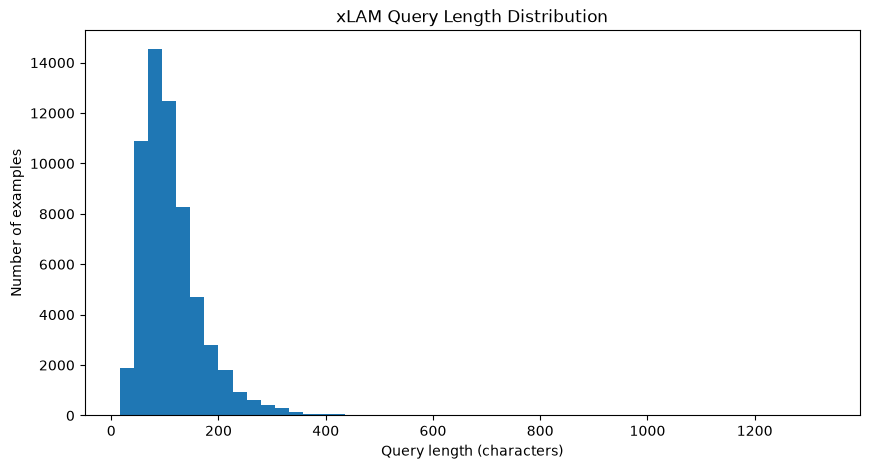

In [12]:
plt.figure(figsize=(10, 5))

plt.hist(
    profile_df["query_length_chars"].dropna(),
    bins=50
)

plt.xlabel("Query length (characters)")
plt.ylabel("Number of examples")
plt.title("xLAM Query Length Distribution")

plt.show()

In [13]:
print("Shortest queries:")
display(
    profile_df
    .sort_values("query_length_chars")
    [["index", "query", "query_length_chars"]]
    .head(10)
)

print("\nLongest queries:")
display(
    profile_df
    .sort_values("query_length_chars", ascending=False)
    [["index", "query", "query_length_chars"]]
    .head(10)
)

Shortest queries:


,index,query,query_length_chars
25263,25263,Can Pikachu run?,16
37158,37158,Generate 10 UUIDs.,18
2003,2003,Generate 10 UUIDs.,18
116,116,Is 27 a power of 3?,19
12279,12279,Is 27 a power of 3?,19
13208,13208,Is 64 a power of 2?,19
20689,20689,Is 64 a power of 2?,19
12023,12023,Roll a 6-sided die.,19
49647,49647,Is 81 a power of 3?,19
3596,3596,Is 64 a power of 2?,19



Longest queries:


,index,query,query_length_chars
57179,57179,Check if the following three Sudoku boards are...,1330
44334,44334,A Sudoku enthusiast has two puzzles to solve a...,975
8400,8400,Can you validate two Sudoku boards? The first ...,935
44400,44400,Check the validity of the following two Sudoku...,921
56714,56714,Check the validity of the following Sudoku boa...,917
49757,49757,Check if the following two Sudoku boards are v...,903
19324,19324,Verify if these two Sudoku boards are valid: [...,897
38659,38659,Suppose you are a financial analyst and you ha...,709
53220,53220,How can I split the following text into chunks...,619
51911,51911,How can I split the following text into chunks...,605


In [14]:
call_distribution = (
    profile_df["num_calls"]
    .value_counts()
    .sort_index()
)

print(call_distribution)

num_calls
1     28461
2     25422
3      4697
4      1056
5       187
6        94
7        20
8        12
9        12
10       19
11        4
12        6
14        2
19        1
20        2
23        1
24        1
26        1
30        1
52        1
Name: count, dtype: int64


In [15]:
call_percentages = (
    profile_df["num_calls"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(call_percentages.round(2))

num_calls
1     47.44
2     42.37
3      7.83
4      1.76
5      0.31
6      0.16
7      0.03
8      0.02
9      0.02
10     0.03
11     0.01
12     0.01
14     0.00
19     0.00
20     0.00
23     0.00
24     0.00
26     0.00
30     0.00
52     0.00
Name: proportion, dtype: float64


In [16]:
print(
    profile_df["num_tools"].describe()
)

count    60000.00000
mean         2.81450
std          1.60361
min          1.00000
25%          1.00000
50%          3.00000
75%          4.00000
max          8.00000
Name: num_tools, dtype: float64


In [17]:
tool_count_distribution = (
    profile_df["num_tools"]
    .value_counts()
    .sort_index()
)

display(tool_count_distribution.head(20))

num_tools
1    15410
2    12726
3    12655
4    13078
5     2427
6     1464
7     1108
8     1132
Name: count, dtype: int64

In [18]:
tool_names = []

for row in dataset:

    tools = parse_json_field(row["tools"])

    if not isinstance(tools, list):
        continue

    for tool in tools:
        if isinstance(tool, dict) and "name" in tool:
            tool_names.append(tool["name"])

print(f"Total tool definitions encountered: {len(tool_names):,}")
print(f"Unique tool names: {len(set(tool_names)):,}")

Total tool definitions encountered: 168,870
Unique tool names: 3,605


In [19]:
unique_tools = sorted(set(tool_names))

for tool in unique_tools[:50]:
    print(tool)

a_chapter_by_its_slug
about
about_channel
account_balance
account_transaction_count
account_transaction_history
active_listings
activities
actors_get_all_filmography
actors_get_all_images
actors_get_awards_summary
actors_get_interesting_jobs
actors_list_born_today
actors_list_most_popular_celebs
actors_random
additional_title_details
addnumbers
address
address_autocomplete
address_autosuggest
address_code
address_inclusion
address_postal_code
address_reverse_geocoding
addresses
addresses_addressid
adosc
advance
advance_profile
advanced
advanced_chart
advanced_phone_number_lookup
advanced_search
advisory_information
africa
age_calculator
agencies_list
agent_details
agent_s_active_listings
agents_get_profile
air_quality_forecast
air_quality_forecasts
air_quality_history
air_quality_measurements
aircraft_scatter_data
airplanes_by_brand
airplanes_ordered_by_ascending
airplanes_ordered_by_descending
airport_arrivals
airport_info


In [20]:
def get_tool_category(tool_name):
    if not isinstance(tool_name, str):
        return None
    
    if "." in tool_name:
        return tool_name.split(".")[0]
    
    return tool_name


tool_categories = [
    get_tool_category(name)
    for name in tool_names
]

category_counts = Counter(tool_categories)

print(f"Observed category-like prefixes: {len(category_counts)}")

for category, count in category_counts.most_common():
    print(f"{category:40} {count}")

Observed category-like prefixes: 3605
search                                   2187
sort_numbers                             763
cell_density                             703
calculate_standard_deviation             689
find_pairs_with_sum                      668
get_ip_zipcode                           654
is_perfect_square                        639
bacterial_growth                         634
find_n_largest_numbers                   624
project_investment_growth                621
final_velocity                           612
calculate_investment_return              605
std_deviation                            603
is_leap_year                             595
numerical_derivative                     593
loginuser                                591
structural_analysis                      590
calculate_electric_field                 589
triangle_area                            587
euclidean_distance                       586
predict_forest_area                      578
simulate_query_d

In [21]:
argument_types = Counter()

for row in dataset:

    tools = parse_json_field(row["tools"])

    if not isinstance(tools, list):
        continue

    for tool in tools:

        if not isinstance(tool, dict):
            continue

        parameters = tool.get("parameters", {})

        if not isinstance(parameters, dict):
            continue

        for param_name, param_info in parameters.items():

            if isinstance(param_info, dict):
                param_type = param_info.get("type", "unknown")
            else:
                param_type = "unknown"

            argument_types[param_type] += 1

print("Argument types:")
for arg_type, count in argument_types.most_common():
    print(f"{arg_type:15} {count:,}")

Argument types:
str             130,067
str, optional   70,623
int             67,509
int, optional   32,701
float           21,818
List[int]       7,865
List[float]     7,385
bool, optional  7,377
float, optional 4,143
list            2,179
List[List[int]] 1,553
List            1,500
List[Union[int, float]] 1,250
Tuple[float, float] 1,172
List[str]       1,055
Dict            988
List[List[float]] 770
Callable[[float], float] 593
set             572
List[Tuple[float, float]] 496
List[List[str]] 424
List[Tuple[int, int]] 226
bool            118
str, default='elonmusk' 36
str, optional, default 'London' 18
str, optional, default='20' 16
str, optional, default='fr-FR' 13
int, optional, default=100 13
str, optional, default='0' 1
str, optional, default='25' 1


In [22]:
required_count = 0
optional_count = 0

for row in dataset:

    tools = parse_json_field(row["tools"])

    if not isinstance(tools, list):
        continue

    for tool in tools:

        if not isinstance(tool, dict):
            continue

        parameters = tool.get("parameters", {})

        if not isinstance(parameters, dict):
            continue

        for _, param_info in parameters.items():

            if not isinstance(param_info, dict):
                continue

            if param_info.get("required") is True:
                required_count += 1
            else:
                optional_count += 1

print("Required parameters:", required_count)
print("Optional parameters:", optional_count)

Required parameters: 0
Optional parameters: 362482


In [23]:
def canonical_json(value):
    try:
        parsed = json.loads(value) if isinstance(value, str) else value
        return json.dumps(
            parsed,
            sort_keys=True,
            separators=(",", ":")
        )
    except Exception:
        return str(value)


def record_hash(row):
    content = (
        row["query"]
        + canonical_json(row["tools"])
        + canonical_json(row["answers"])
    )

    return hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()

In [24]:
hashes = [
    record_hash(row)
    for row in dataset
]

hash_counts = Counter(hashes)

duplicate_records = sum(
    count - 1
    for count in hash_counts.values()
    if count > 1
)

print("Total records:", len(dataset))
print("Unique records:", len(hash_counts))
print("Exact duplicate records:", duplicate_records)

Total records: 60000
Unique records: 59625
Exact duplicate records: 375


In [25]:
profile_df["complexity_score"] = (
    profile_df["num_tools"].fillna(0)
    + profile_df["num_calls"].fillna(0) * 2
    + profile_df["query_length_chars"].fillna(0) / 500
)

In [26]:
candidate_difficult = (
    profile_df
    .sort_values("complexity_score", ascending=False)
    .head(20)
)

display(
    candidate_difficult[
        [
            "index",
            "num_tools",
            "num_calls",
            "query_length_chars",
            "complexity_score",
            "query"
        ]
    ]
)

,index,num_tools,num_calls,query_length_chars,complexity_score,query
40513,40513,1,52,65,105.130,Get tide information for station 8418150 on ev...
12549,12549,5,30,54,65.108,Get rugby fixtures for the entire month of Apr...
50260,50260,1,26,97,53.194,What were the railway periods for the UTC date...
6420,6420,4,23,70,50.140,Retrieve pit stop data for all rounds of the F...
59732,59732,1,24,77,49.154,Could you provide me with the earnings data fo...
58947,58947,2,20,93,42.186,Get earnings information for the 10 largest co...
59801,59801,1,20,71,41.142,What is the smallest number that is the sum of...
53185,53185,2,19,79,40.158,Find the longest palindromic substring in the ...
36224,36224,4,14,127,32.254,What are the trading signals for BTC on Binanc...
44674,44674,2,14,221,30.442,Retrieve the daily financial reports for the f...


In [27]:
summary = {
    "total_examples": len(dataset),
    "unique_exact_records": len(hash_counts),
    "exact_duplicate_records": duplicate_records,
    "invalid_tool_json": int((~profile_df["tools_valid_json"]).sum()),
    "invalid_answer_json": int((~profile_df["answers_valid_json"]).sum()),
    "missing_queries": int(profile_df["query"].isna().sum()),
    "avg_query_length": profile_df["query_length_chars"].mean(),
    "median_query_length": profile_df["query_length_chars"].median(),
    "max_query_length": profile_df["query_length_chars"].max(),
    "avg_available_tools": profile_df["num_tools"].mean(),
    "avg_tool_calls": profile_df["num_calls"].mean(),
    "max_tool_calls": profile_df["num_calls"].max(),
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["metric", "value"]
)

display(summary_df)

,metric,value
0,total_examples,60000.00000
1,unique_exact_records,59625.00000
2,exact_duplicate_records,375.00000
3,invalid_tool_json,0.00000
4,invalid_answer_json,0.00000
5,missing_queries,0.00000
6,avg_query_length,111.89315
7,median_query_length,100.00000
8,max_query_length,1330.00000
9,avg_available_tools,2.81450
